In [1]:
# Install dependencies for YOLO inference and segmentation evaluation
!pip install -q ultralytics opencv-python-headless scikit-learn pandas matplotlib seaborn tqdm pillow

In [2]:
from google.colab import drive
from pathlib import Path

# Mount Google Drive
drive.mount("/content/drive")

# Define project directories
PROJECT_DIR = Path("/content/drive/MyDrive/KoraAI")
DATASET_DIR = PROJECT_DIR / "vision" / "test_images"

# Display dataset directories
print("PROJECT DIRECTORY:", PROJECT_DIR)
print("DATASET DIRECTORY:", DATASET_DIR)

# Verify dataset availability
assert DATASET_DIR.exists(), "Dataset directory not found!"

print("\nGoogle Drive connected successfully!")

Mounted at /content/drive
PROJECT DIRECTORY: /content/drive/MyDrive/KoraAI
DATASET DIRECTORY: /content/drive/MyDrive/KoraAI/vision/test_images

Google Drive connected successfully!


In [3]:
# Search for YOLO model weights in Google Drive
print("Searching for YOLO model weights...")

model_files = list(
    PROJECT_DIR.rglob("best.pt")
)

# Display discovered model files
if model_files:
    print("\nMODEL FILES FOUND:")

    for index, model_path in enumerate(model_files, start=1):
        print(f"{index}. {model_path}")
else:
    print("\nNo best.pt file was found.")
    print("The model weights must be uploaded to Google Drive.")

Searching for YOLO model weights...

No best.pt file was found.
The model weights must be uploaded to Google Drive.


In [4]:
from google.colab import drive
from pathlib import Path
from huggingface_hub import hf_hub_download
import shutil

# Mount Google Drive if it is not already mounted
drive.mount("/content/drive")

# Define project and model directories
PROJECT_DIR = Path("/content/drive/MyDrive/KoraAI")
MODEL_DIR = PROJECT_DIR / "models" / "food_segmentation"

# Create the model directory
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Download the pretrained food segmentation model
downloaded_model = hf_hub_download(
    repo_id="arunapb/yolo11l-food-segmentation",
    filename="best.pt"
)

# Copy the model weights to Google Drive
MODEL_PATH = MODEL_DIR / "best.pt"
shutil.copy2(downloaded_model, MODEL_PATH)

# Verify the downloaded model
print("MODEL DOWNLOAD COMPLETED")
print("-------------------------")
print("Model path:", MODEL_PATH)
print("Model size (MB):", round(MODEL_PATH.stat().st_size / (1024**2), 2))

assert MODEL_PATH.exists()

print("\nModel weights verified successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


best.pt: reconstructing file:   0%|          |  0.00B /  222MB            

best.pt: downloading bytes:           |  0.00B            

MODEL DOWNLOAD COMPLETED
-------------------------
Model path: /content/drive/MyDrive/KoraAI/models/food_segmentation/best.pt
Model size (MB): 211.8

Model weights verified successfully!


In [5]:
from ultralytics import YOLO

# Load the pretrained food segmentation model
model = YOLO(str(MODEL_PATH))

# Inspect model configuration
print("MODEL INFORMATION")
print("-----------------")
print("Task:", model.task)
print("Number of classes:", len(model.names))

print("\nCLASS NAMES:")
for class_id, class_name in model.names.items():
    print(f"{class_id}: {class_name}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
MODEL INFORMATION
-----------------
Task: segment
Number of classes: 1

CLASS NAMES:
0: food


In [6]:
import torch

# Load checkpoint metadata
checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=False
)

# Inspect checkpoint structure
print("CHECKPOINT KEYS:", list(checkpoint.keys()))

# Inspect training configuration
train_args = checkpoint.get("train_args", {})

print("\nTRAINING CONFIGURATION")
print("----------------------")
print("Single class:", train_args.get("single_cls"))
print("Dataset configuration:", train_args.get("data"))

# Inspect stored model metadata
for model_key in ["model", "ema"]:
    stored_model = checkpoint.get(model_key)

    if stored_model is not None:
        print(f"\n{model_key.upper()} METADATA")
        print("Classes:", getattr(stored_model, "names", None))
        print("Number of classes:", getattr(stored_model, "nc", None))
        print("Model configuration:", getattr(stored_model, "yaml", {}).get("nc"))

CHECKPOINT KEYS: ['epoch', 'best_fitness', 'model', 'ema', 'updates', 'optimizer', 'scaler', 'train_args', 'train_metrics', 'train_results', 'date', 'version', 'git', 'license', 'docs']

TRAINING CONFIGURATION
----------------------
Single class: False
Dataset configuration: /kaggle/working/food_combined/data.yaml

EMA METADATA
Classes: {0: 'food'}
Number of classes: 1
Model configuration: 1


In [7]:
import pandas as pd

# Load multiple-food annotations
annotations = pd.read_csv(
    DATASET_DIR / "annotations" / "segmentation_annotations.csv"
)

# Select the first test image
sample = annotations.iloc[0]
sample_image = DATASET_DIR / "multiple_foods" / sample["file_name"]

# Run food segmentation inference
results = model.predict(
    source=str(sample_image),
    conf=0.25,
    save=True,
    retina_masks=True
)

# Display prediction information
result = results[0]

print("IMAGE:", sample["file_name"])
print("EXPECTED FOODS:", sample["food_items"])
print("DETECTED OBJECTS:", len(result.boxes))
print("SEGMENTATION MASKS:", 0 if result.masks is None else len(result.masks.data))


image 1/1 /content/drive/MyDrive/KoraAI/vision/test_images/multiple_foods/MULTI_001.jpg: 448x640 10 foods, 1777.0ms
Speed: 15.4ms preprocess, 1777.0ms inference, 49.6ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/runs/segment/predict
IMAGE: MULTI_001.jpg
EXPECTED FOODS: red beans; egg; grape; chicken duck; potato; tomato; lettuce; green beans; french beans
DETECTED OBJECTS: 10
SEGMENTATION MASKS: 10


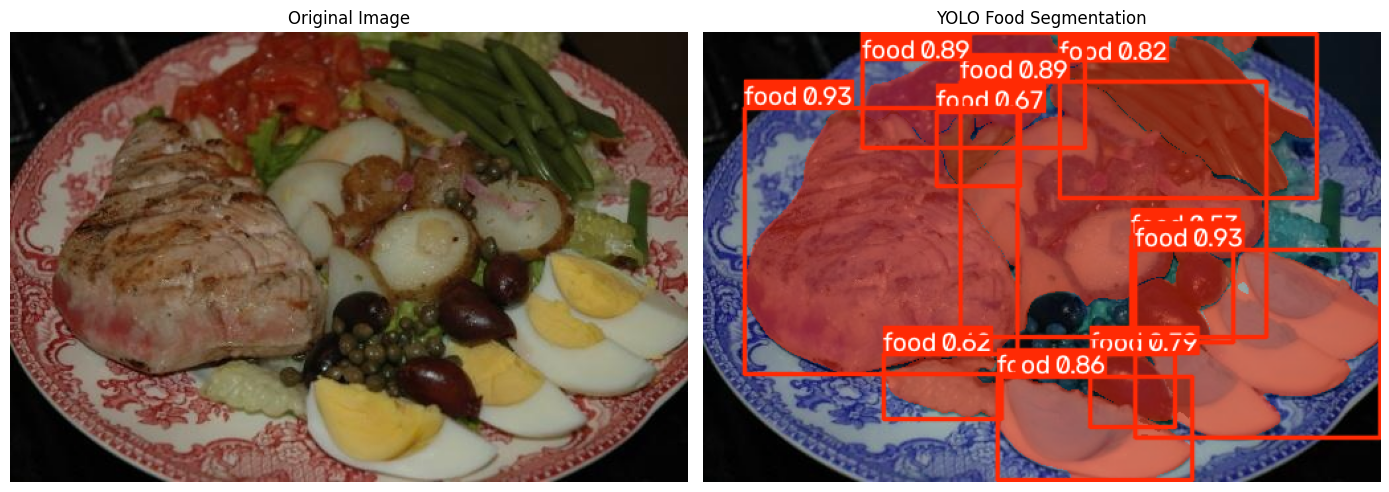

In [8]:
import matplotlib.pyplot as plt

# Display original image and YOLO segmentation prediction
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# Show original image
axes[0].imshow(plt.imread(sample_image))
axes[0].set_title("Original Image")
axes[0].axis("off")

# Show segmentation prediction
axes[1].imshow(result.plot())
axes[1].set_title("YOLO Food Segmentation")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [9]:
import pandas as pd

# Load segmentation annotations
multiple_df = pd.read_csv(
    DATASET_DIR / "annotations" / "segmentation_annotations.csv"
)

mixed_df = pd.read_csv(
    DATASET_DIR / "annotations" / "mixed_dish_annotations.csv"
)

# Check duplicated source samples
overlap = set(multiple_df["source_sample_id"]) & set(mixed_df["source_sample_id"])

print("MULTIPLE-FOOD IMAGES:", len(multiple_df))
print("MIXED-DISH IMAGES:", len(mixed_df))
print("DUPLICATED SOURCE SAMPLES:", len(overlap))

# Combine evaluation annotations
evaluation_df = pd.concat(
    [multiple_df, mixed_df],
    ignore_index=True
)

# Display evaluation dataset summary
print("\nEVALUATION DATASET")
print("------------------")
print("Total images:", len(evaluation_df))
print("Total masks:", evaluation_df["mask_file"].notna().sum())

assert len(evaluation_df) == 60
assert evaluation_df["mask_file"].notna().all()

print("\nEvaluation dataset prepared successfully!")

MULTIPLE-FOOD IMAGES: 40
MIXED-DISH IMAGES: 20
DUPLICATED SOURCE SAMPLES: 3

EVALUATION DATASET
------------------
Total images: 60
Total masks: 60

Evaluation dataset prepared successfully!


In [10]:
# Identify duplicated source samples
duplicate_rows = mixed_df[
    mixed_df["source_sample_id"].isin(overlap)
]

# Display duplicated image information
print("DUPLICATED IMAGES")
print("-----------------")

for _, row in duplicate_rows.iterrows():
    print(
        f"Image: {row['file_name']} | "
        f"Source ID: {row['source_sample_id']}"
    )

DUPLICATED IMAGES
-----------------
Image: MIXED_002.jpg | Source ID: 1943
Image: MIXED_005.jpg | Source ID: 829
Image: MIXED_006.jpg | Source ID: 2077


In [11]:
# Remove duplicated source samples from mixed-dish annotations
mixed_unique_df = mixed_df[
    ~mixed_df["source_sample_id"].isin(overlap)
].copy()

# Build the final evaluation dataset
evaluation_df = pd.concat(
    [multiple_df, mixed_unique_df],
    ignore_index=True
).reset_index(drop=True)

# Display final dataset statistics
print("FINAL EVALUATION DATASET")
print("------------------------")
print("Multiple-food images:", len(multiple_df))
print("Mixed-dish images:", len(mixed_unique_df))
print("Total unique images:", len(evaluation_df))
print("Reference masks:", evaluation_df["mask_file"].notna().sum())

# Verify dataset integrity
assert len(evaluation_df) == 57
assert evaluation_df["mask_file"].notna().all()
assert evaluation_df["source_sample_id"].is_unique

print("\nEvaluation dataset ready!")

FINAL EVALUATION DATASET
------------------------
Multiple-food images: 40
Mixed-dish images: 17
Total unique images: 57
Reference masks: 57

Evaluation dataset ready!


In [14]:
import cv2
import numpy as np
from tqdm.auto import tqdm
import time

# Initialize evaluation results
evaluation_results = []

# Process every image in the evaluation dataset
for _, row in tqdm(evaluation_df.iterrows(), total=len(evaluation_df)):

    # Define image and ground-truth mask paths
    image_path = DATASET_DIR / (
        "multiple_foods" if row["image_id"].startswith("MULTI")
        else "mixed_dishes"
    ) / row["file_name"]

    # Define the ground-truth mask path
    mask_path = DATASET_DIR / "annotations" / row["mask_file"]

    # Load ground-truth segmentation mask
    ground_truth = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

    # Convert ground-truth mask into binary food/background mask
    ground_truth = (ground_truth > 0).astype(np.uint8)

    # Run YOLO segmentation inference
    start_time = time.perf_counter()

    prediction = model.predict(
        source=str(image_path),
        conf=0.25,
        retina_masks=True,
        verbose=False
    )[0]

    inference_time = time.perf_counter() - start_time

    # Create an empty binary prediction mask
    predicted_mask = np.zeros_like(ground_truth, dtype=np.uint8)

    # Combine all detected food instance masks
    if prediction.masks is not None:
        masks = prediction.masks.data.cpu().numpy()

        for instance_mask in masks:
            resized_mask = cv2.resize(
                instance_mask,
                (ground_truth.shape[1], ground_truth.shape[0]),
                interpolation=cv2.INTER_NEAREST
            )

            predicted_mask[resized_mask > 0.5] = 1

    # Calculate intersection and union
    intersection = np.logical_and(
        ground_truth == 1,
        predicted_mask == 1
    ).sum()

    union = np.logical_or(
        ground_truth == 1,
        predicted_mask == 1
    ).sum()

    # Calculate IoU and Dice score
    iou = intersection / union if union > 0 else 1.0

    denominator = ground_truth.sum() + predicted_mask.sum()
    dice = (2 * intersection / denominator) if denominator > 0 else 1.0

    # Store image-level evaluation metrics
    evaluation_results.append({
        "image_id": row["image_id"],
        "scenario": row["scenario"],
        "detections": len(prediction.boxes),
        "iou": iou,
        "dice": dice,
        "inference_time_ms": inference_time * 1000
    })

print("Segmentation evaluation completed!")
print("Images evaluated:", len(evaluation_results))

  0%|          | 0/57 [00:00<?, ?it/s]

Segmentation evaluation completed!
Images evaluated: 57


In [15]:
import pandas as pd

# Convert evaluation results into a DataFrame
results_df = pd.DataFrame(evaluation_results)

# Calculate overall evaluation metrics
summary = results_df[[
    "iou",
    "dice",
    "inference_time_ms",
    "detections"
]].agg(["mean", "median", "min", "max"])

# Display overall results
print("YOLO SEGMENTATION EVALUATION")
print("============================")
print("\nOVERALL METRICS")
display(summary.round(4))

# Calculate metrics by scenario
print("\nMETRICS BY SCENARIO")
display(
    results_df.groupby("scenario")[
        ["iou", "dice", "inference_time_ms", "detections"]
    ].mean().round(4)
)

YOLO SEGMENTATION EVALUATION

OVERALL METRICS


,iou,dice,inference_time_ms,detections
mean,0.8959,0.9418,2425.5467,9.0
median,0.9441,0.9713,2227.7894,9.0
min,0.6000,0.7500,1734.5263,4.0
max,0.9862,0.9931,4156.6371,18.0



METRICS BY SCENARIO


,iou,dice,inference_time_ms,detections
scenario,,,,
mixed_dishes,0.8971,0.9411,2310.7998,8.0588
multiple_foods,0.8954,0.9421,2474.3141,9.4000


In [16]:
# Identify images with the lowest segmentation IoU
worst_results = (
    results_df
    .merge(
        evaluation_df[["image_id", "file_name"]],
        on="image_id"
    )
    .sort_values("iou", ascending=True)
    .head(5)
)

# Display the five most challenging images
print("FIVE LOWEST SEGMENTATION RESULTS")
print("--------------------------------")
display(
    worst_results[
        ["image_id", "file_name", "scenario", "iou", "dice", "detections"]
    ].round(4)
)

FIVE LOWEST SEGMENTATION RESULTS
--------------------------------


,image_id,file_name,scenario,iou,dice,detections
50,MIXED_014,MIXED_014.jpg,mixed_dishes,0.6000,0.7500,9
39,MULTI_040,MULTI_040.jpg,multiple_foods,0.6074,0.7558,10
47,MIXED_011,MIXED_011.jpg,mixed_dishes,0.6314,0.7741,13
23,MULTI_024,MULTI_024.jpg,multiple_foods,0.6786,0.8085,6
32,MULTI_033,MULTI_033.jpg,multiple_foods,0.7129,0.8324,9


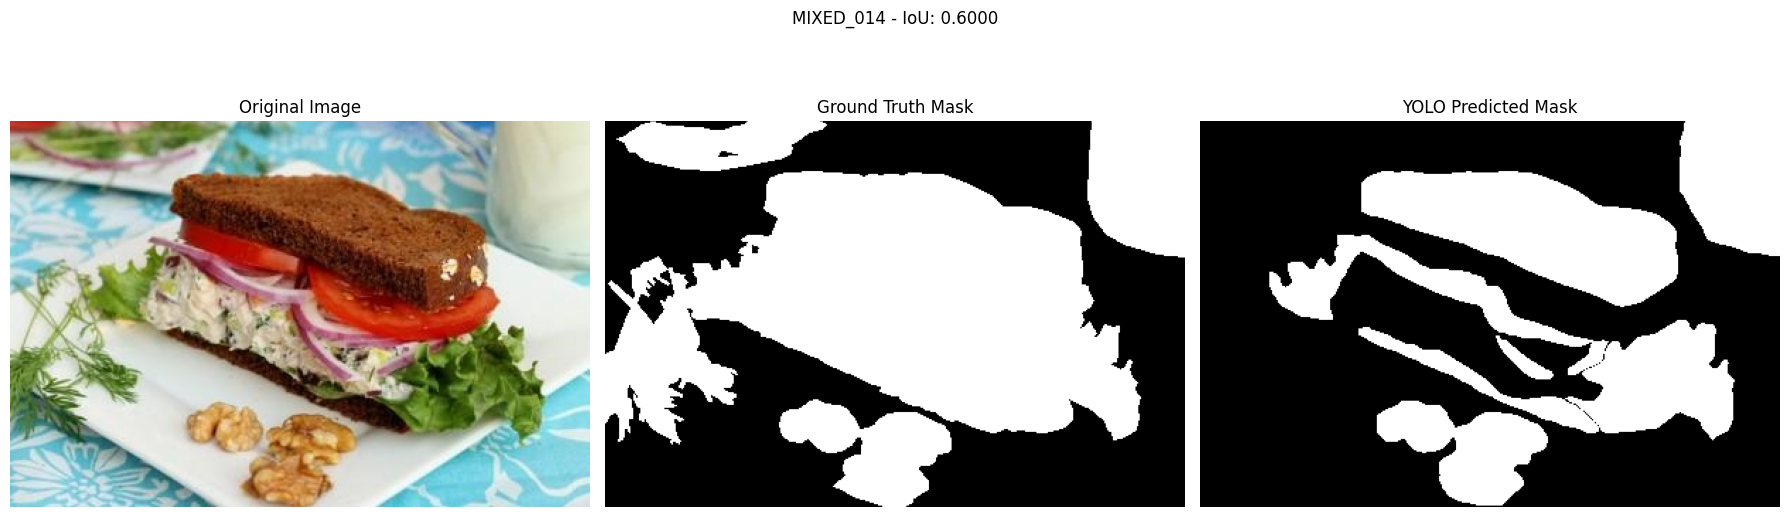

In [17]:
import matplotlib.pyplot as plt
import cv2
import numpy as np

# Select the image with the lowest IoU
worst_image = worst_results.iloc[0]

# Define image and mask paths
image_path = DATASET_DIR / "mixed_dishes" / worst_image["file_name"]
mask_path = DATASET_DIR / "annotations" / evaluation_df.loc[
    evaluation_df["image_id"] == worst_image["image_id"],
    "mask_file"
].iloc[0]

# Load original image and ground-truth mask
original = cv2.cvtColor(
    cv2.imread(str(image_path)),
    cv2.COLOR_BGR2RGB
)

ground_truth = cv2.imread(
    str(mask_path),
    cv2.IMREAD_GRAYSCALE
)

ground_truth = (ground_truth > 0).astype(np.uint8)

# Run YOLO inference
prediction = model.predict(
    source=str(image_path),
    conf=0.25,
    retina_masks=True,
    verbose=False
)[0]

# Generate binary prediction mask
predicted_mask = np.zeros_like(ground_truth)

if prediction.masks is not None:
    for instance_mask in prediction.masks.data.cpu().numpy():
        resized_mask = cv2.resize(
            instance_mask,
            (ground_truth.shape[1], ground_truth.shape[0]),
            interpolation=cv2.INTER_NEAREST
        )
        predicted_mask[resized_mask > 0.5] = 1

# Display comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(original)
axes[0].set_title("Original Image")

axes[1].imshow(ground_truth, cmap="gray")
axes[1].set_title("Ground Truth Mask")

axes[2].imshow(predicted_mask, cmap="gray")
axes[2].set_title("YOLO Predicted Mask")

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"{worst_image['image_id']} - IoU: {worst_image['iou']:.4f}"
)
plt.tight_layout()
plt.show()